In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("cars.csv")

rows,cols = df.shape

names = []

for i in range(rows):

    fullName = ""

    fullName = fullName + df.loc[i, "First Name"]

    fullName = fullName + " " + df.loc[i, "Last Name"]

    names.append(fullName)

df.insert(0, "Name", names)

df = df[["Name", "Country", "Car Brand", "Car Model", "Car Color", "Year of Manufacture", "Credit Card Type"]]

# Check for duplicates 
# print(df.duplicated().sum())

# Check for null values
# print(df.isnull().sum())

display(df)

,Name,Country,Car Brand,Car Model,Car Color,Year of Manufacture,Credit Card Type
0,Yetty Arghent,Indonesia,Ford,Club Wagon,Teal,1993,mastercard
1,Crystal Bosworth,China,Cadillac,Escalade ESV,Fuscia,2007,mastercard
2,Monro Houdhury,Indonesia,Mazda,Miata MX-5,Orange,2009,maestro
3,Bowie Clair,China,Audi,A4,Orange,2005,instapayment
4,Myrvyn McAllister,Czech Republic,Nissan,Maxima,Pink,1994,maestro
...,...,...,...,...,...,...,...
29995,Valida Smoote,Afghanistan,Nissan,Altima,Yellow,2010,jcb
29996,Anthea Deport,Indonesia,Kia,Rio,Red,2008,china-unionpay
29997,Albertine Danelut,Japan,Toyota,Tacoma Xtra,Pink,2004,americanexpress
29998,Alayne Golda,Kyrgyzstan,Audi,riolet,Turquoise,1996,americanexpress


# Analysis 2: Does mean car age differ between USA and China
We want to examine whether mean car age (year of manufacture) is different depending on if the buyer is from USA or China. To test this, a two sample t test will be used. Since we are comparing two countries, comparing means, car age is numeric, groups are indy, and pop sd is not known, two sample t test is best

https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html

In [41]:
df['Country'].value_counts()
df[df['Country'] == 'United States'].shape[0]

633

In [22]:
#get df for usa and china
usa_df = df[df['Country'] == 'United States']
china_df = df[df['Country'] == 'China']
usa_df.head()
 

,Name,Country,Car Brand,Car Model,Car Color,Year of Manufacture,Credit Card Type,Country_with_Other
12,Artemis Wrenn,United States,Hyundai,Elantra,Red,2000,maestro,United States
130,Hasty Covolini,United States,Lamborghini,Countach,Crimson,1988,laser,United States
177,Salomon Zanetto,United States,Toyota,Corolla,Crimson,2007,jcb,United States
190,Josephine Torregiani,United States,Buick,Riviera,Violet,1985,laser,United States
192,Cristiano Pummell,United States,Pontiac,LeMans,Goldenrod,1964,jcb,United States


In [ ]:
# use only years of manufacture for analysis
usa_years = usa_df['Year of Manufacture']
china_years = china_df['Year of Manufacture']
usa_years.head()

12     2000
130    1988
177    2007
190    1985
192    1964
Name: Year of Manufacture, dtype: int64

In [ ]:
# get mean and std dev for usa and china
usa_mean = usa_years.mean()
china_mean = china_years.mean()

usa_std = usa_years.std()
china_std = china_years.std()

print("USA Mean:", usa_mean)
print("China Mean:", china_mean)
print("USA Std Dev:", usa_std)
print("China Std Dev:", china_std)

USA Mean: 2000.172195892575
China Mean: 2000.3096065873742
USA Std Dev: 9.542230473912353
China Std Dev: 9.279933025864178


In [ ]:
# do a t-test to see if the means are significantly different
import scipy.stats as stats
t, p = stats.ttest_ind(usa_years, china_years, equal_var=False)

In [28]:
print("t statistic:", t)
print("p-value:", p)

t statistic: -0.3439533090945807
p-value: 0.730974460775725


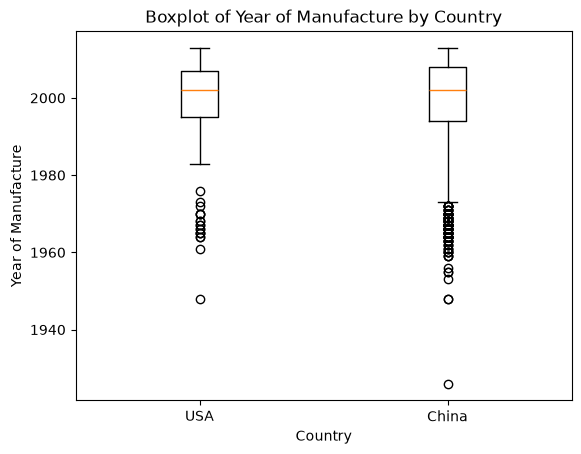

In [ ]:
# make box plot to compare the distributions of year of manufacture for USA and China
import matplotlib.pyplot as plt

plt.boxplot([usa_years, china_years])
plt.xticks([1, 2], ['USA', 'China'])
plt.title('Boxplot of Year of Manufacture by Country')
plt.xlabel('Country')
plt.ylabel('Year of Manufacture')
plt.show()

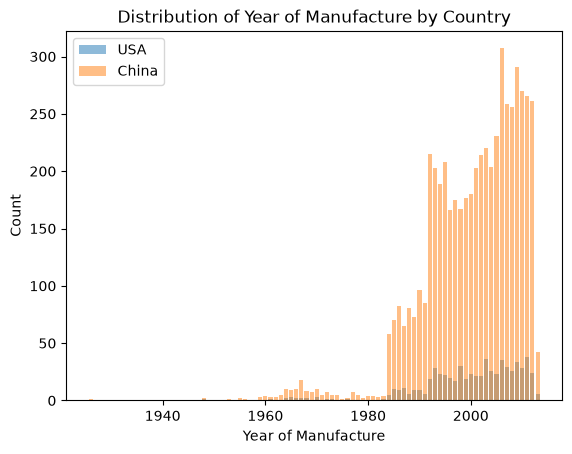

In [ ]:
# make bar plot to compare the distributions of year of manufacture for USA and China
plt.bar(usa_years.value_counts().index, usa_years.value_counts().values, alpha=0.5, label='USA')
plt.bar(china_years.value_counts().index, china_years.value_counts().values, alpha=0.5, label='China')
plt.xlabel('Year of Manufacture')
plt.ylabel('Count')
plt.title('Distribution of Year of Manufacture by Country')
plt.legend()
plt.show()

Since the p value is .73 > .05, we fail to reject the null hypothesis. There was not statistically significant evidence that indicates the mean year of manufacture between USA and China is significanlty different. 

This can also be seen in the box plot. Although the spread of manufacture dates is different, with China having a heavier skew towards older cars than the USA, the means are roughly the same. The reasoning for this can be seen in the bar chart. Even though china has a larger spread from 1960 to 1980, they have a huge number of purchases made around 2000, bringing its mean back up 